<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg", align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.875 · Deep Learning · PEC1</p>
<p style="margin: 0; text-align:right;">2025-2 · Máster universitario en Ciencia de datos (Data science)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>


# PEC 1: Redes neuronales convolucionales con Keras y Pytorch - Clasificación de imágenes satelitales

A lo largo de esta práctica vamos a implementar varios modelos de redes neuronales para clasificar las imágenes de una base de datos de imágenes satelitales. Concretamente se desarrollaran las siguientes tareas:
1. Descarga, análisis y pre-procesado de los datos (1.5 pts)
2. Red neuronal completamente conectada (Dense NN) (1.5 pts)
3. Red convolucional (CNN) pequeña (2 pts)
4. Autoencoders (2 pts)
5. Transfer Learning con modelos eficientes: EfficientNetB0 (2 pts)
6. Introducción a Pytorch: Replicando nuestra CNN (1 pt)

<u>Consideraciones generales</u>:

- La solución propuesta no debe utilizar métodos, funciones o parámetros declarados **_deprecated_** en versiones futuras.
- Esta PEC se debe hacer de manera **estrictamente individual**. Cualquier indicio de copia será penalizado con un suspenso (D) para todas las partes implicadas y la posible evaluación negativa de la totalidad de la asignatura.
- Es necesario que el estudiante indique **todas las fuentes** que ha utilizado para la realización de la PEC. En caso contrario, se considerará que el alumno ha cometido plagio, siendo penalizado con un suspenso (D) y la posible evaluación negativa de la totalidad de la asignatura.
- Si se utiliza cualquier **IA generativa** en la resolución del PAC **se debe referenciar** en aquellas secciones donde se ha utilizado, como cualquier otra fuente.

<u>Formato de la entrega</u>:

- Algunos ejercicios pueden suponer varios minutos de ejecución, de manera que la entrega se debe hacer en formato **Notebook** y en formato **html**, donde se vea el código, los resultados y los comentarios de cada ejercicio. Podéis exportar el cuaderno a HTML en Jupyter Notebook desde el menú File $\to$ Download as $\to$ HTML.
- Hay un tipo especial de celda para alojar el texto. Este tipo de celdas será muy útil para responder a las diferentes preguntas teóricas planteadas a lo largo de la actividad. Para cambiar el tipo de celda a este tipo, en el menú: Cell $\to$ Cell Type $\to$ Markdown.

<u>Dataset utilizado</u>:

En este PAC utilizaremos **UC Merced Land Use Dataset**, un conjunto de datos de libre acceso que consta de imágenes aéreas de alta resolución (2 m) de una región agrícola en el Valle Central de California.

## 0. Contexto y carga de librerías
Las imágenes tomadas por satélite son clave en la supervisión del uso y la cobertura del suelo, cuestiones relevantes para la gestión ambiental, la planificación urbana, la sostenibilidad y para combatir el cambio climático.

En esta práctica, trabajaremos con la base de datos [UC Merced Land Use Data](https://www.kaggle.com/datasets/zeadomar/uc-mercedland), que consiste en imágenes satelitales de 256x256 píxeles de 21 escenas diferentes: las clases son diversas, y contienen escenas e imágenes de aviones o ríos, entre otras categorías.

Concretamente trabajaremos con una versión aumentada de dicha base de datos que está disponible en un [repositorio de Kaggle](https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification). En esta versión se han llevado a cabo varios procesos de aumentación de datos de tal forma que el número de imágenes por clase pasa de 100 a 500.

**Nota: Se recomienda realizar la práctica en el entorno que ofrece la plataforma Kaggle, ya que ofrece un entorno gratuito con 30 horas semanales de uso de GPU.**

A lo largo de toda la práctica, para la creación de las distintas redes, iremos alternando el uso del modelo [Sequential](https://keras.io/guides/sequential_model/) y el modelo [Functional](https://keras.io/guides/functional_api/) de Keras a través de las clases [Sequential](https://keras.io/api/models/sequential/) y [Model](https://keras.io/api/models/model/) respectivamente.

Empezamos cargando las librerías mas relevantes:

In [4]:
# Importamos tensorflow
import tensorflow as tf
print("TF version   : ", tf.__version__)

# Necesitaremos GPU
print("GPU available: ", tf.config.list_physical_devices('GPU'))

# keras version is 2.11.0
import keras
print("Keras version   : ", keras.__version__)

TF version   :  2.19.0
GPU available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Keras version   :  3.13.2


In [5]:
# Importamos los elementos de keras que utilizaremos con mayor frecuencia
from keras.utils import image_dataset_from_directory
from keras.layers import (
    GlobalAveragePooling2D, Flatten,
    Dense, Dropout, Conv2D, Conv2DTranspose, BatchNormalization,
    MaxPooling2D, UpSampling2D, Rescaling, Resizing)
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from keras import Sequential, Model

In [6]:
# Importamos el resto de librerías que necesitaremos para la PEC
import cv2
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from PIL import Image
from tqdm.auto import tqdm
import json

from tensorflow.keras.layers import Rescaling

# Procesamiento paralelo
from concurrent.futures import ThreadPoolExecutor


## 1. Descarga, análisis y pre-procesado de los datos (1,5 puntos)

En este apartado exploraremos la base de datos y prepararemos la carga de las imágenes para los modelos de los siguientes apartados.

Para la descarga de la base de datos tenemos 2 opciones dependiendo de si decidimos trabajar en local o desde el entorno de Kaggle:
- Si trabajamos en local debemos descargar la base de datos desde el siguiente [enlace](https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification/download?datasetVersionNumber=3) (es un archivo .zip que ocupa 2 GB) y descomprimirlo.
- Si trabajamos desde Kaggle. Debemos subir el Notebook del enunciado a la plataforma (para ello podéis seguir los 6 primeros pasos del siguiente [artículo](https://rajputankit22.medium.com/how-to-upload-my-own-notebook-to-kaggle-2b0dedbb5a6b)) y después, una vez subido el notebook, en la pestaña 'Input', clickar el botón '+ Add Input' y en la caja de búsqueda introducir la dirección 'https://www.kaggle.com/datasets/apollo2506/landuse-scene-classification'. Una vez encontrado el dataset darle al botón '+' (Add Dataset), y desde ese momento ya tendréis accesible la base de datos en la ruta <code>../input/</code>.

Una vez tenemos la base de datos accesible vamos a inspeccionarla.

Las imágenes se encuentran agrupadas de 2 formas diferentes:
- En la carpeta <code>/landuse-scene-classification/images/</code> se encuentra el total de las imágenes separadas por clases (cada clase en una carpeta distinta). Pero no se ha realizado una separación en conjunto de entrenamiento y test (o entrenamiento, validación y test).
- En la carpeta <code>/landuse-scene-classification/images_train_test_val/</code> se encuentran 3 carpetas (<code>test</code>, <code>train</code> y <code>validation</code>) en las que el total de imágenes se ha separado de forma aleatoria. En cada una de las 3 carpetas, tenemos imágenes de las 21 clases agrupadas en sus correspondientes carpetas. En la carpeta raíz <code>/landuse-scene-classification/</code> tenemos 3 archivos .csv con la distribución de cada carpeta.

En esta práctica utilizaremos el dataset ya particionado, es decir, trabajaremos con las imágenes que se encuentran en la ruta <code>/landuse-scene-classification/images_train_test_val/</code>.

### 1.1. Análisis de los archivos .csv

A partir de los archivos .csv podemos ver cómo se han distribuído los datos. Por ejemplo:

In [7]:
# Conexión a la fuente de datos

from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv('/content/drive/MyDrive/PEC1 UOC Deep Learning/Data/train.csv')

Mounted at /content/drive


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio [0,5 pts.]:</strong> A partir de los 3 archivos .csv se pide:
    <ul>
        <li>Extraer los nombres de las 21 clases (esto sólo hace falta hacerlo en uno de los 3 archivos)</li>
        <li>¿Cuántas instancias tenemos en total para cada conjunto de datos?</li>
        <li>Comprobar que las clases están balanceadas en los 3 conjuntos de datos (contando para cada conjunto, cuantas instancias/ejemplos tenemos para cada clase)</li>
    </ul>        
</div>

In [8]:
# Extraer nombres de las clases



# AJUSTAR ESTA RUTA SEGÚN CORRESPONDA PARA ACCEDER A LOS DIRECTORIOS
data_dir = "/content/drive/MyDrive/PEC1 UOC Deep Learning/Data"

# Se eligió train.csv pero se puede cambiar a cualquier otro poniendo el nombre}
# como parámetro de os.path.join(data_dir, "nombreArchivo.csv")

csv_file = os.path.join(data_dir, "train.csv")
json_file = os.path.join(data_dir, "label_map.json")

df = pd.read_csv(csv_file)
print("Columnas:", list(df.columns))

# Heurística: posibles nombres de columna de clase
candidates = ["label", "class", "category", "target", "class_name", "classname", "name",
              "label_id", "class_id", "category_id", "target_id", "Label", "ClassName"]

label_col = None
for c in candidates:
    if c in df.columns:
        label_col = c
        break
# Control de errores
if label_col is None:
    raise ValueError("No se encontró una columna de clase. Revisar las columnas impresas arriba.")

# Caso A: ya viene como texto (nombres)
if df[label_col].dtype == "object":
    classes = sorted(df[label_col].dropna().unique())
    print(f"\n Clases encontradas en '{label_col}' (total {len(classes)}):")
    for i, cls in enumerate(classes, 1):
        print(f"{i:02d}. {cls}")

# Caso B: viene como id numérico, usamos label_map.json
else:
    if not os.path.exists(json_file):
        raise ValueError(f"'{label_col}' parece ser numérico, pero no existe {json_file} para mapear ids a nombres.")
    with open(json_file, "r", encoding="utf-8") as f:
        label_map = json.load(f)

    # Se normaliza keys por si vienen como strings
    # label_map puede ser { "0": "cat", ... } o { "cat": 0, ... }
    # Se detecta orientación:
    sample_key = next(iter(label_map.keys()))
    if str(sample_key).isdigit():  # {id: name}
        id_to_name = {int(k): v for k, v in label_map.items()}
    else:  # {name: id}
        id_to_name = {int(v): k for k, v in label_map.items()}

    ids = sorted(df[label_col].dropna().unique())
    classes = [id_to_name[i] for i in ids]

    print(f"\n Clases encontradas vía '{label_col}' + label_map.json (total {len(classes)}):")
    for i, cls in enumerate(classes, 1):
        print(f"{i:02d}. {cls}")


Columnas: ['Unnamed: 0', 'Filename', 'Label', 'ClassName']

 Clases encontradas vía 'Label' + label_map.json (total 21):
01. agricultural
02. airplane
03. baseballdiamond
04. beach
05. buildings
06. chaparral
07. denseresidential
08. forest
09. freeway
10. golfcourse
11. intersection
12. mediumresidential
13. mobilehomepark
14. overpass
15. parkinglot
16. river
17. runway
18. sparseresidential
19. storagetanks
20. tenniscourt
21. harbor


In [9]:
# Número de instancias por conjunto

# Para cada conjunto (train / validation / test), el número de instancias es
# simplemente el número de filas del CSV (sin contar el header).


files = {
    "train": "train.csv",
    "validation": "validation.csv",
    "test": "test.csv",
}

for split, fname in files.items():
    path = os.path.join(data_dir, fname)
    df = pd.read_csv(path)
    print(f"{split:10s}: {len(df):,} instancias  |  columnas: {df.shape[1]}")

train     : 7,350 instancias  |  columnas: 4
validation: 2,100 instancias  |  columnas: 4
test      : 1,050 instancias  |  columnas: 4


In [10]:
# Número de instancias por clase


files = {
    "train": "train.csv",
    "validation": "validation.csv",
    "test": "test.csv",
}

# Usar nombres de clase
label_col = "ClassName"

for split, fname in files.items():
    df = pd.read_csv(os.path.join(data_dir, fname))
    counts = df[label_col].value_counts().sort_index()

    print(f"\n=== {split.upper()} ===")
    print(f"Total instancias: {len(df)}")
    print(counts)

    mn, mx = counts.min(), counts.max()
    print(f"min={mn} | max={mx} | max/min={mx/mn:.3f}")


=== TRAIN ===
Total instancias: 7350
ClassName
agricultural         350
airplane             350
baseballdiamond      350
beach                350
buildings            350
chaparral            350
denseresidential     350
forest               350
freeway              350
golfcourse           350
harbor               350
intersection         350
mediumresidential    350
mobilehomepark       350
overpass             350
parkinglot           350
river                350
runway               350
sparseresidential    350
storagetanks         350
tenniscourt          350
Name: count, dtype: int64
min=350 | max=350 | max/min=1.000

=== VALIDATION ===
Total instancias: 2100
ClassName
agricultural         100
airplane             100
baseballdiamond      100
beach                100
buildings            100
chaparral            100
denseresidential     100
forest               100
freeway              100
golfcourse           100
harbor               100
intersection         100
mediumresident

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentarios:</strong>
<br><br>
Los tres conjuntos están perfectamente balanceados, ya que todas las clases tienen exactamente el mismo número de instancias en cada split (350/100/50), y el ratio max/min = 1.000 en train, validation y test.
<br><br>
</div>

### 1.2. Análisis de las carpetas de imágenes.

Aunque se supone que cada archivo .csv refleja a la perfección el contenido de cada conjunto de datos, no está demás cerciorarse que el contenido del mismo se corresponde con lo anotado en cada archivo. Para ello se pide:

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio[0,5 pts]:</strong> Proporciona, a partir de las carpetas de imágenes, el número de imágenes que tenemos en cada categoría para cada conjunto de datos, comprobando que coincide con lo estipulado en el archivo .csv, y visualiza a modo de ejemplo una imagen por cada categoría. ¿Qué rango dinámico (valores mínimo y máximo) tienen las imágenes?
</div>

In [55]:
# Esta es una celda común para los tres puntos solicitados.



CSV_PATHS = {
    "train": os.path.join(data_dir, "train.csv"),
    "validation": os.path.join(data_dir, "validation.csv"),
    "test": os.path.join(data_dir, "test.csv"),
}

# Se detectará la carpeta de imágenes

IMG_ROOT_CANDIDATES = [
    os.path.join(data_dir, "images_train_test_val"),
    os.path.join(data_dir, "images"),
    data_dir,
]

def resolve_split_root(split_name: str, example_relpath: str) -> str:
    """
    Devuelve la ruta base para el split (train/validation/test) tal que:
    os.path.join(split_root, example_relpath) exista.

    NOTA: Función reusable para los 3 conjuntos solicitados.
    """
    for root in IMG_ROOT_CANDIDATES:
        # Caso A: root ya contiene las imágenes del split directamente
        p = os.path.join(root, example_relpath)
        if os.path.exists(p):
            return root

        # Caso B: root/split contiene las imágenes
        p2 = os.path.join(root, split_name, example_relpath)
        if os.path.exists(p2):
            return os.path.join(root, split_name)

        # Caso C: validation a veces es "val"
        if split_name == "validation":
            p3 = os.path.join(root, "val", example_relpath)
            if os.path.exists(p3):
                return os.path.join(root, "val")

    raise FileNotFoundError(
        "No se puede detectar la carpeta de imágenes automáticamente.\n"
    )

def count_images_in_folder_by_class(split_root: str, classes: list, ext=(".png",".jpg",".jpeg",".bmp",".tif",".tiff",".webp")):
    """
    Cuenta imágenes por clase leyendo carpetas:
    split_root/<ClassName>/*.(ext)

    NOTA: Función reusable para los 3 conjuntos solicitados.
    """
    counts = {}
    for c in classes:
        class_dir = os.path.join(split_root, c)
        n = 0
        if os.path.isdir(class_dir):
            for e in ext:
                n += len(glob.glob(os.path.join(class_dir, f"*{e}")))
        counts[c] = n
    return pd.Series(counts).sort_index()


def dynamic_range_from_filelist(file_list):
    """
    Calcula min y max de píxeles recorriendo imágenes.

    OPTIMIZACIÓN: paraleliza lectura/decodificación con threads y procesa en chunks grandes.

    NOTA: Función reusable para los 3 conjuntos solicitados.
    """
    gmin, gmax = None, None

    # Ajustes (chunk grande + threads)
    WORKERS = 64   # threads para I/O + decodificación
    print("Número de hilos:" + str(WORKERS))
    ## Se aumentó el chunk de 512 a 1024 para mejorar el tiempo de procesamiento
    CHUNK_SIZE = 1024 # chunk grande

    def minmax_one(fp):
        # Abrir y cerrar dentro del thread
        with Image.open(fp) as im:
            arr = np.asarray(im)  # Convertir a array
        return int(arr.min()), int(arr.max())

    with tqdm(total=len(file_list), desc="Calculando rango dinámico") as pbar:
        with ThreadPoolExecutor(max_workers=WORKERS) as ex:
            for i in range(0, len(file_list), CHUNK_SIZE):
                batch = file_list[i:i+CHUNK_SIZE]
                for mn, mx in ex.map(minmax_one, batch):
                    gmin = mn if gmin is None else min(gmin, mn)
                    gmax = mx if gmax is None else max(gmax, mx)
                pbar.update(len(batch))

    return gmin, gmax

def show_one_image_per_class(split_root: str, classes: list, ncols=7):
    """
    Visualiza 1 imagen por clase (la primera encontrada en la carpeta).

    NOTA: Función reusable para los 3 conjuntos solicitados.
    """
    n = len(classes)
    nrows = (n + ncols - 1) // ncols

    plt.figure(figsize=(3*ncols, 3*nrows))
    for i, c in enumerate(classes):
        class_dir = os.path.join(split_root, c)
        img_files = []
        for e in (".png",".jpg",".jpeg",".bmp",".tif",".tiff",".webp"):
            img_files += glob.glob(os.path.join(class_dir, f"*{e}"))

        ax = plt.subplot(nrows, ncols, i+1)
        if img_files:
            img = Image.open(img_files[0])
            ax.imshow(img)
        ax.set_title(c, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

def analyze_split(split_name: str):
    """
    - Cuenta por clase usando CSV (esperado)
    - Cuenta por clase usando carpetas (real)
    - Comprueba coincidencia
    - Visualiza 1 imagen por clase
    - Rango dinámico min/max

    NOTA: Función reusable para los 3 conjuntos solicitados.
    """
    df = pd.read_csv(CSV_PATHS[split_name])

    # Columnas reales
    CLASS_COL = "ClassName"
    FILE_COL  = "Filename"

    classes = sorted(df[CLASS_COL].unique())

    # Detectar split_root a partir de una ruta real en el CSV
    example_rel = df[FILE_COL].iloc[0]  # ej: runway/runway_000259.png
    split_root = resolve_split_root(split_name, example_rel)

    # Conteo por clase según CSV
    csv_counts = df[CLASS_COL].value_counts().sort_index()

    # Conteo por clase según carpetas
    folder_counts = count_images_in_folder_by_class(split_root, classes)

    # Comparación de conteo de clases según CSV <-> clase según carpetas
    comp = pd.DataFrame({
        "csv": csv_counts.reindex(classes).fillna(0).astype(int),
        "carpeta": folder_counts.reindex(classes).fillna(0).astype(int),
    })
    comp["diff(carpeta-csv)"] = comp["carpeta"] - comp["csv"]

    print(f"\n=== {split_name.upper()} ===")
    print("Split root:", split_root)
    print("Total CSV:", len(df), "| Total carpeta:", int(comp["carpeta"].sum()))
    display(comp)

    mism = comp[comp["diff(carpeta-csv)"] != 0]
    if len(mism) == 0:
        print(" Coincide EXACTO carpeta vs CSV para todas las clases.")
    else:
        print("Hay diferencias. Revisar estas clases:")
        display(mism)

    # Visualizar una imagen por clase
    print("\n Ejemplo: 1 imagen por clase")
    show_one_image_per_class(split_root, classes)

    # Rango dinámico: se calculará leyendo SOLO las imágenes listadas en el CSV
    file_list = [os.path.join(split_root, rel) for rel in df[FILE_COL].tolist()]
    # Asegurar de que existan (por si hay rutas raras)
    file_list = [fp for fp in file_list if os.path.exists(fp)]

    mn, mx = dynamic_range_from_filelist(file_list)
    print(f"\n Rango dinámico ({split_name}): min={mn}, max={mx}")


=== TRAIN ===
Split root: /content/drive/MyDrive/PEC1 UOC Deep Learning/Data/images_train_test_val/train
Total CSV: 7350 | Total carpeta: 7350


,csv,carpeta,diff(carpeta-csv)
agricultural,350,350,0
airplane,350,350,0
baseballdiamond,350,350,0
beach,350,350,0
buildings,350,350,0
chaparral,350,350,0
denseresidential,350,350,0
forest,350,350,0
freeway,350,350,0
golfcourse,350,350,0


 Coincide EXACTO carpeta vs CSV para todas las clases.

 Ejemplo: 1 imagen por clase


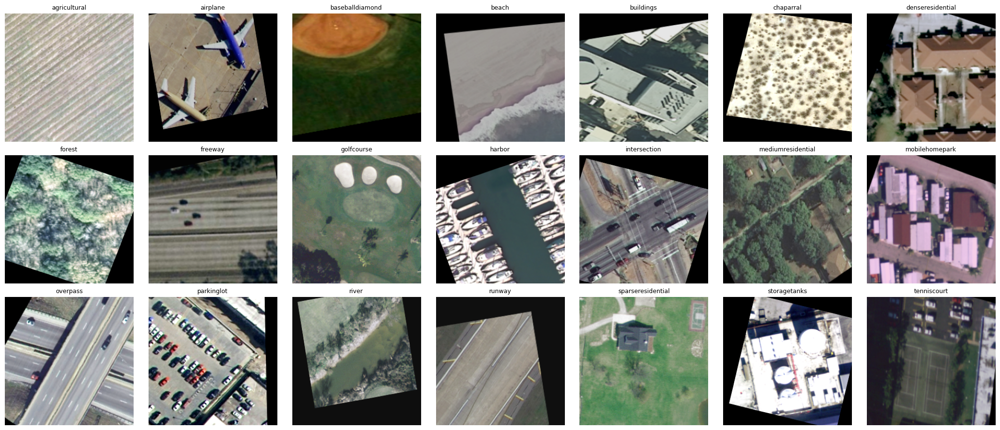

Número de hilos:64


Calculando rango dinámico:   0%|          | 0/7350 [00:00<?, ?it/s]


 Rango dinámico (train): min=0, max=255


In [15]:

# Para el conjunto de datos de entrenamiento
analyze_split("train")


=== VALIDATION ===
Split root: /content/drive/MyDrive/PEC1 UOC Deep Learning/Data/images_train_test_val/validation
Total CSV: 2100 | Total carpeta: 2100


,csv,carpeta,diff(carpeta-csv)
agricultural,100,100,0
airplane,100,100,0
baseballdiamond,100,100,0
beach,100,100,0
buildings,100,100,0
chaparral,100,100,0
denseresidential,100,100,0
forest,100,100,0
freeway,100,100,0
golfcourse,100,100,0


 Coincide EXACTO carpeta vs CSV para todas las clases.

 Ejemplo: 1 imagen por clase


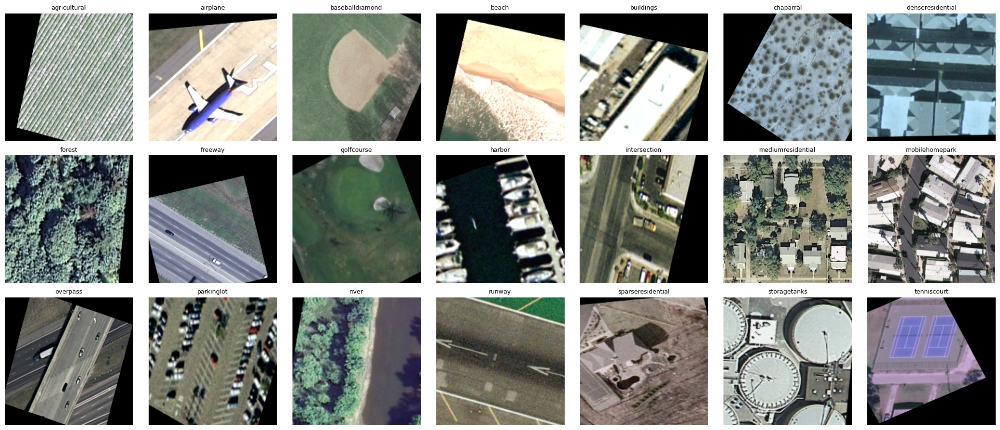

Número de hilos:64


Calculando rango dinámico:   0%|          | 0/2100 [00:00<?, ?it/s]


 Rango dinámico (validation): min=0, max=255


In [16]:
# Para el conjunto de datos de validación
analyze_split("validation")


=== TEST ===
Split root: /content/drive/MyDrive/PEC1 UOC Deep Learning/Data/images_train_test_val/test
Total CSV: 1050 | Total carpeta: 1050


,csv,carpeta,diff(carpeta-csv)
agricultural,50,50,0
airplane,50,50,0
baseballdiamond,50,50,0
beach,50,50,0
buildings,50,50,0
chaparral,50,50,0
denseresidential,50,50,0
forest,50,50,0
freeway,50,50,0
golfcourse,50,50,0


 Coincide EXACTO carpeta vs CSV para todas las clases.

 Ejemplo: 1 imagen por clase


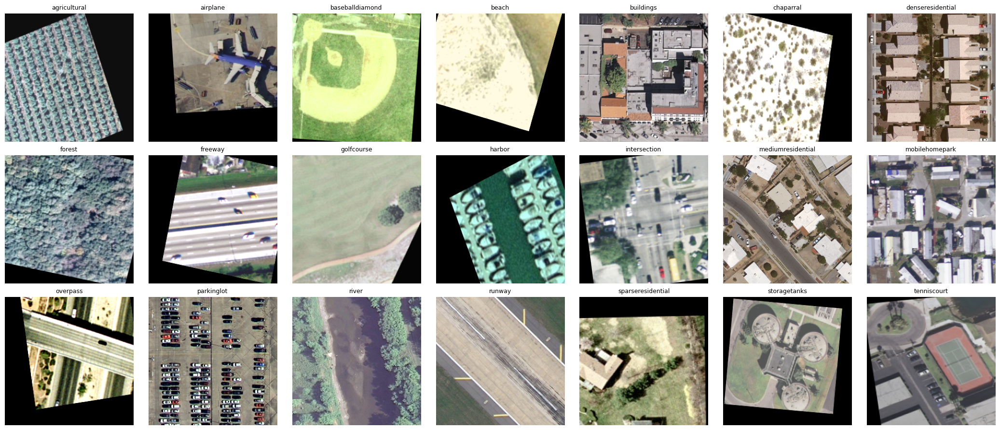

Número de hilos:64


Calculando rango dinámico:   0%|          | 0/1050 [00:00<?, ?it/s]


 Rango dinámico (test): min=0, max=255


In [17]:
# Para el conjunto de datos de test
analyze_split("test")

### 1.3. Creación de los conjuntos de datos en formato Keras/Tensorflow
​
Con el objetivo de crear una base de datos en el formato Keras/Tensorflow a partir de las imágenes proporcionadas utilizaremos la función <code>**tf.keras.utils.image_dataset_from_directory()**</code> ya que nos permite crear bases de datos a partir de imágenes guardadas en carpetas.

La documentación de esta función se encuentra tanto en la web de [Keras](https://keras.io/api/data_loading/image/) como en la de [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory) .

Además, aprovecharemos para redimensionar las imágenes y pasarlas a tamaño 224x224, que es el tamaño con el que se ha entrenado la red EfficientNetB0 que utilizaremos en un apartado posterior.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio[0,5 pts]:</strong> Utiliza la función  <code>image_dataset_from_directory()</code> para generar 3 conjuntos de datos (<code>train_data</code>, <code>val_data</code> y <code>test_data</code>) a partir de las carpetas analizadas. Las imágenes deben ser redimensionadas a tamaño 224x224 píxels RGB (224,224,3) y agrupadas en lotes de tamaño 32 (batch=32) manteniendo su rango dinámico.
</div>

In [18]:
# RUTAS
BASE_IMG_DIR = "/content/drive/MyDrive/PEC1 UOC Deep Learning/Data/images_train_test_val"
TRAIN_DIR = os.path.join(BASE_IMG_DIR, "train")
VAL_DIR   = os.path.join(BASE_IMG_DIR, "validation")
TEST_DIR  = os.path.join(BASE_IMG_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

def make_ds(dir_path, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        dir_path,
        labels="inferred",
        label_mode="int",
        color_mode="rgb",
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,          # Se redimensiona a 224x224
        shuffle=shuffle,
        seed=SEED
    )
    # Mantener rango dinámico: image_dataset_from_directory devuelve float32 en [0,255]
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_data = make_ds(TRAIN_DIR, shuffle=True)
val_data   = make_ds(VAL_DIR, shuffle=False)
test_data  = make_ds(TEST_DIR, shuffle=False)

# MODIFICACIÓN AÑADIDA (aceleración I/O y pipeline)
# Si se desea pasar a la ejecución de las épocas SIN OPTIMIZACIÓN elimine las
# siguientes tres (3) líneas de código

train_data = train_data.cache().prefetch(tf.data.AUTOTUNE)
val_data   = val_data.cache().prefetch(tf.data.AUTOTUNE)
test_data  = test_data.cache().prefetch(tf.data.AUTOTUNE)

#############################################################################

print("Datasets creados y optimizados con cache+prefetch:")
print("train:", train_data)
print("val:  ", val_data)
print("test: ", test_data)

# Verificar rango dinámico real en un batch
for x, y in train_data.take(1):
    print("Batch shape:", x.shape, y.shape)
    print("dtype:", x.dtype)
    print("min:", tf.reduce_min(x).numpy(), "max:", tf.reduce_max(x).numpy())

Found 7350 files belonging to 21 classes.
Found 2100 files belonging to 21 classes.
Found 1050 files belonging to 21 classes.
Datasets creados y optimizados con cache+prefetch:
train: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
val:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
test:  <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Batch shape: (32, 224, 224, 3) (32,)
dtype: <dtype: 'float32'>
min: 0.0 max: 255.0


## 2. Red neuronal completamente conectada (Dense NN) (1,5 puntos)

En este apartado, vamos a entrenar y evaluar un modelo muy sencillo completamente conectado para establecer un resultado de referencia.

Dado que en una red neuronal artificial las entradas son unidimensionales, lo primero que tenemos que hacer es redimensionar los datos de entrada (las imágenes) para convertirlos en arrays de una dimensión.

Como trabajar con imágenes de tamaño 224x224 en una red completamente conectada implicaría entrenar un número de parámetros excesivamente elevado definiremos un modelo en el que se realizará previamente un redimensionado de las imágenes de entrada a un tamaño de 32x32 y un achatamiento (*flattening*) de los píxeles para así generar un vector unidimensional de tamaño 3072 (32x32x3).

Posteriormente entrenaremos un clasificador (una red completamente conectada) para llevar a cabo la clasificación de nuestros datos.

En este apartado utilizaremos las capas [Resizing](https://keras.io/api/layers/preprocessing_layers/image_preprocessing/resizing/), [Rescaling](https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/), [Flatten](https://keras.io/api/layers/reshaping_layers/flatten/), [Dense](https://keras.io/api/layers/core_layers/dense/) y [Dropout](https://keras.io/api/layers/regularization_layers/dropout/) de keras.


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
    <strong>Ejercicio:</strong> Implementa un modelo <strong>secuencial</strong> de Keras (a partir de la clase <code>Sequential()</code>) con las siguientes especificaciones:
    <ul>
        <li>Una capa que reduzca las dimensiones de entrada de (224,224) a (32,32)</li>
        <li>Una capa de reescalado para conseguir que los valores de la imagen estén entre 0 y 1</li>
        <li>Una capa Flatten para convertir la imagen en un vector de 3072 posiciones</li>
        <li>Una capa completamente conectada de 1024 neuronas y activación ReLU</li>
        <li>Una capa de Dropout (con probabilidad 0.5)</li>
        <li>Una capa de salida completamente conectada correspondiente a la clasificación final cuyo número de neuronas debe ser igual al múmero de clases de la base de datos y con la función de activación adecuada para llevar a cabo esta tarea de clasificación.</li>
    </ul>
        
Compilar y entrenar el modelo siguiendo las siguientes indicaciones:
     <ul>
         <li>Utilizar el optimizador Adam con  <i>learning rate</i> de 0.0001.</li>
         <li>Entrenar durante 100 épocas utilizando  <i>EarlyStopping</i> con una persistencia de 10 épocas, monitorizando la función de pérdida en el conjunto de validación, y guardando los pesos que mejor resultado hayan obtenido.</li>
         <li>Monitorizar la métrica  <i>accuracy</i> durante entrenamiento y validación.</li>
         <li>Mostrar las gráficas de accuracy y loss. En cada gráfica debe visualizarse la curva de entrenamiento y la de validación. NOTA: Se recomienda hacer una función que imprima ambas gráficas para poder reutilizarla en próximos apartados.</li>
         <li>Realizar la evaluación del modelo una vez ha finalizado el entrenamiento para mostrar la pérdida y la exactitud final sobre los datos de test.</li>
    </ul>
    Preguntas a responder: ¿Cúal es el número de parámetros a entrenar? ¿y el tiempo de entrenamiento? ¿Qué precisión se obtiene con este modelo? Comenta los resultados y las gráficas de entrenamiento.<br/>    
    <strong> NOTA: se recomienda, al final de la creación de cada modelo, utilizar la función <code>summary()</code> para comprobar la estructura de la red creada, así como el numero de parámetros que se deben entrenar. Se recomienda hacerlo en todos los ejercicios.</strong>
</div>

In [19]:
# Definición de la red



num_classes = len(classes)

dense_model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    tf.keras.layers.Resizing(32, 32),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1024, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │        21,525 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,168,277 (12.09 MB)

 Trainable params: 3,168,277 (12.09 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Compilación de la red

opt = tf.keras.optimizers.Adam(learning_rate=1e-4)

dense_model.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",   # etiquetas int (0..20)
    metrics=["accuracy"]
)

In [21]:
# Entrenamiento de la red

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_dense = dense_model.fit(
    train_data,
    validation_data=val_data,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 29s 104ms/step - accuracy: 0.0622 - loss: 3.1158 - val_accuracy: 0.0952 - val_loss: 2.9966
Epoch 2/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0841 - loss: 3.0029 - val_accuracy: 0.1190 - val_loss: 2.9816
Epoch 3/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1076 - loss: 2.9567 - val_accuracy: 0.1190 - val_loss: 2.9488
Epoch 4/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1203 - loss: 2.9172 - val_accuracy: 0.1310 - val_loss: 2.9159
Epoch 5/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1384 - loss: 2.8725 - val_accuracy: 0.1548 - val_loss: 2.8861
Epoch 6/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1497 - loss: 2.8373 - val_accuracy: 0.1671 - val_loss: 2.8465
Epoch 7/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1611 - loss: 2.7972 - val_accuracy: 0.1657 - val_loss: 2.8334
Epoch 8/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1722 - loss: 2.7539 - val_a

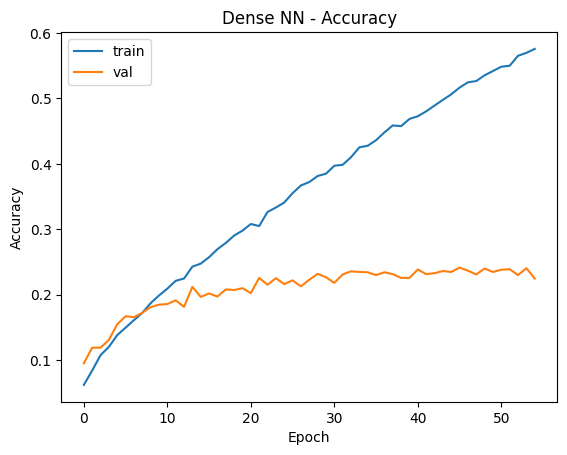

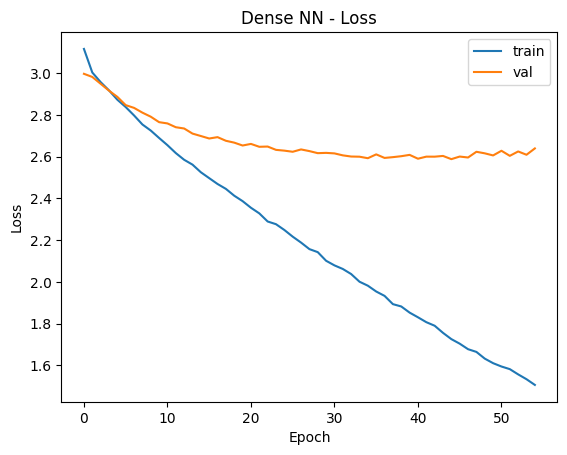

Mejor época: 45 mejor val_loss: 2.587778329849243
Épocas entrenadas: 55


In [22]:
# Plot del training loss y la accuracy



def plot_history(history, title_prefix=""):
    # Accuracy
    plt.figure()
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"{title_prefix}Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["train", "val"])
    plt.show()

    # Loss
    plt.figure()
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"{title_prefix}Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["train", "val"])
    plt.show()

plot_history(history_dense, title_prefix="Dense NN - ")


best_epoch = int(np.argmin(history_dense.history["val_loss"])) + 1
best_val = min(history_dense.history["val_loss"])
print("Mejor época:", best_epoch, "mejor val_loss:", best_val)
print("Épocas entrenadas:", len(history_dense.history["loss"]))

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentarios:</strong>
<br><br>

**Optimización del tiempo de entrenamiento.** Durante las primeras épocas se observó que el entrenamiento era muy lento debido al coste de lectura/decodificación de imágenes desde Drive. Para acelerar el proceso, se optimizó el input pipeline aplicando cache() y prefetch(tf.data.AUTOTUNE) sobre los datasets, lo que redujo drásticamente el tiempo por época (una vez cargada la información en la caché). Esta optimización no modifica los datos ni el modelo, únicamente mejora la eficiencia del suministro de batches al entrenamiento.

**EarlyStopping y mejor época.** El entrenamiento se configuró con EarlyStopping monitorizando val_loss con patience=10 y restore_best_weights=True. El mejor rendimiento en validación se alcanzó en la época 45, con val_loss = 2.5878. A partir de ahí, el val_loss no volvió a mejorar durante 10 épocas consecutivas, por lo que el entrenamiento se detuvo en la época 55, restaurando automáticamente los pesos correspondientes a la mejor época (55).

**Interpretación de las gráficas (accuracy y loss).** En la curva de accuracy, la precisión de entrenamiento crece de forma sostenida (superando ~0.5), mientras que la precisión de validación aumenta al inicio pero luego se estabiliza alrededor de ~0.23–0.25. En la curva de loss, la pérdida de entrenamiento desciende continuamente, mientras que la pérdida de validación disminuye al comienzo pero después se aplana y deja de mejorar (en torno a ~2.6). Este patrón indica que el modelo sigue ajustándose cada vez mejor al conjunto de entrenamiento, pero las mejoras no se trasladan al conjunto de validación, lo que es consistente con sobreentrenamiento y con la limitada capacidad de generalización de un modelo fully-connected aplicado a imágenes (especialmente tras reducir a 32×32 y aplicar flatten, perdiendo estructura espacial).

<br><br>
</div>

## 3. Red convolucional pequeña (2 puntos)

Dadas las bajas prestaciones del modelo anterior vamos a probar otro tipo de redes con el objetivo de obtener unos mejores resultados en la tarea de clasificación que debemos llevar a cabo.

Las redes convolucionales (CNN) son especialmente adecuadas para modelar datos donde hay patrones en 2 dimensiones, como es el caso de las imágenes.

En la tarea de clasificación, la estructura de una CNN se divide en dos grandes bloques:

* **Bloque extractor de características**: En este bloque se generan diferentes niveles de abstracción de la imagen de entrada mediante capas convolucionales. Cuanto más profundas son estas capas, más preparadas están para la tarea de clasificación.
* **Clasificador**: Este bloque está formado por capas totalmente conectadas, la salida de este bloque será la probabilidad asociada a cada clase.

En el apartado anterior, el bloque "extractor de características" era extremadamente simple, por no decir inexistente. En este apartado, vamos a hacer uso de capas convolucionales para poder aprender mejores abstracciones de las imágenes de entrada con el fin de mejorar su clasificación.

En este apartado utilizaremos las capas [Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/),  [MaxPooling2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/), [GlobalAveragePooling2D](https://keras.io/api/layers/pooling_layers/global_average_pooling2d/), [Dense](https://keras.io/api/layers/core_layers/dense/) y [Dropout](https://keras.io/api/layers/regularization_layers/dropout/) de keras.

**Nota: Se recomienda, a partir de este punto realizar el entrenamiento en una máquina con GPU (puede activarse en plataformas como Google Colab o Kaggle) con el fin de reducir los tiempos de entrenamiento.**

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
    <strong>Ejercicio [2 puntos]:</strong> A partir del modelo <strong>funcional</strong> de keras (y la clase <code>Model()</code>), implementa una red con las siguientes características:
    <ul>
        <li>Un bloque extractor de características que conste de:
            <ul>
                <li>Una capa de entrada de dimensiones adecuadas a los datos.</li>
                <li>Una capa de rescalado para conseguir que los valores de la imagen estén entre 0 y 1.</li>
                <li>3 capas convolucionales con tamaño de kernel (5x5) para la primera y (3x3) para las 2 siguientes. Se utilizará padding '<i>same</i>' y activación ReLU. El número de filtros para cada capa convolucional será 16, 32 y 64 respectivamente.</li>
                <li>A cada capa convolucional le sigue una capa de <i>Max Pooling</i></li>
                <li>Una capa de <i>average pooling</i> (GlobalAveragePooling2D) para reducir las dimensiones a un vector de 64 dimensiones.</li>
            </ul></li>
        <li>El clasificador final sigue la estructura del modelo del apartado anterior:
            <ul>
                <li>Una capa completamente conectada de 1024 neuronas y activación ReLU</li>
                <li>Una capa de Dropout (con probabilidad 0.5)</li>
                <li>Una capa de salida completamente conectada correspondiente a la clasificación final cuyo número de neuronas debe ser igual al múmero de clases de la base de datos y con la función de activación adecuada para llevar a cabo esta tarea de clasificación.</li>
            </ul></li>
    </ul>
    
Compilar y entrenar el modelo siguiendo las siguientes indicaciones:
     <ul>
         <li>Utilizar el optimizador Adam con  <i>learning rate</i> de 0.001.</li>
          <li>Entrenar durante 100 épocas utilizando  <i>EarlyStopping</i> con una persistencia de 10 épocas, monitorizando la función de pérdida en el conjunto de validación, y guardando los pesos que mejor resultado hayan obtenido.</li>
         <li>Monitorizar la métrica  <i>accuracy</i> durante entrenamiento y validación.</li>
         <li>Mostrar las gráficas de <i>accuracy</i> y <i>loss</i>. En cada gráfica debe visualizarse la curva de entrenamiento y la de validación.</li>
         <li>Realizar la evaluación del modelo una vez ha finalizado el entrenamiento para mostrar la pérdida y la exactitud final sobre los datos de test.</li>
    </ul>
    Preguntas a responder: ¿Cúal es el número de parámetros a entrenar? ¿y el tiempo de entrenamiento? ¿Qué precisión se obtiene con este modelo? Comenta los resultados y las gráficas de entrenamiento.
</div>

In [23]:
# Definición de la red


num_classes = len(classes)

inputs = tf.keras.Input(shape=(224, 224, 3), name="input_224x224x3")
x = tf.keras.layers.Rescaling(1./255, name="rescale_0_1")(inputs)

# Conv(5x5, 16) + MaxPool
x = tf.keras.layers.Conv2D(16, (5,5), padding="same", activation="relu", name="conv1_5x5_16")(x)
x = tf.keras.layers.MaxPooling2D(name="pool1")(x)

# Conv(3x3, 32) + MaxPool
x = tf.keras.layers.Conv2D(32, (3,3), padding="same", activation="relu", name="conv2_3x3_32")(x)
x = tf.keras.layers.MaxPooling2D(name="pool2")(x)

# Conv(3x3, 64) + MaxPool
x = tf.keras.layers.Conv2D(64, (3,3), padding="same", activation="relu", name="conv3_3x3_64")(x)
x = tf.keras.layers.MaxPooling2D(name="pool3")(x)

# GAP -> vector 64
x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)

# Clasificador
x = tf.keras.layers.Dense(1024, activation="relu", name="dense_1024")(x)
x = tf.keras.layers.Dropout(0.5, name="dropout_0_5")(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="output_softmax")(x)

cnn_small = tf.keras.Model(inputs=inputs, outputs=outputs, name="CNN_small")

cnn_small.summary()

Model: "CNN_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_224x224x3 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_5x5_16 (Conv2D)           │ (None, 224, 224, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_3x3_32 (Conv2D)           │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_3x3_64 (Conv2D)           │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1024 (Dense)              │ (None, 1024)           │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0_5 (Dropout)           │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 21)             │        21,525 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,437 (439.21 KB)

 Trainable params: 112,437 (439.21 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Compilación de la red


opt = tf.keras.optimizers.Adam(learning_rate=0.001)

cnn_small.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [25]:
# Entrenamiento


early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

start_time = time.time()

history_cnn_small = cnn_small.fit(
    train_data,
    validation_data=val_data,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

train_time_sec = time.time() - start_time
print(f"Tiempo total entrenamiento: {train_time_sec/60:.2f} min")
print(f"Épocas entrenadas: {len(history_cnn_small.history['loss'])}")

Epoch 1/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 21s 58ms/step - accuracy: 0.0962 - loss: 2.8754 - val_accuracy: 0.1743 - val_loss: 2.6047
Epoch 2/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.1976 - loss: 2.4919 - val_accuracy: 0.2571 - val_loss: 2.3308
Epoch 3/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.2762 - loss: 2.2363 - val_accuracy: 0.3100 - val_loss: 2.1351
Epoch 4/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.3424 - loss: 2.0205 - val_accuracy: 0.3814 - val_loss: 1.9393
Epoch 5/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.3909 - loss: 1.8619 - val_accuracy: 0.4248 - val_loss: 1.8193
Epoch 6/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.4401 - loss: 1.7124 - val_accuracy: 0.4786 - val_loss: 1.6382
Epoch 7/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.4763 - loss: 1.5977 - val_accuracy: 0.5419 - val_loss: 1.4590
Epoch 8/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.5082 - loss: 1.4903 -

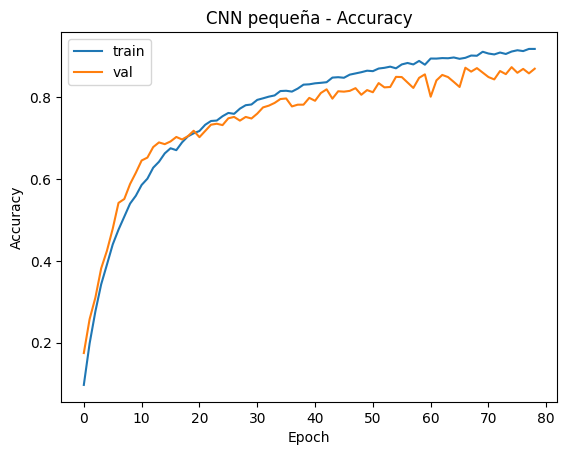

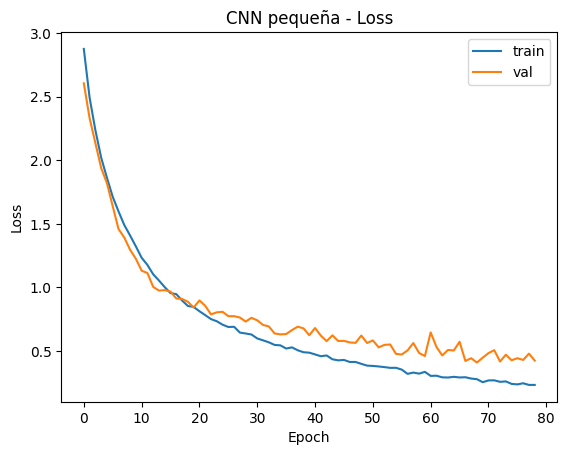

33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 150ms/step - accuracy: 0.8657 - loss: 0.3969
Test loss: 0.3969
Test accuracy: 0.8657
Mejor época (por val_loss): 69
Mejor val_loss: 0.4090
Mejor val_accuracy: 0.8743


In [26]:
# Resultados

def plot_history(history, title_prefix=""):
    # Accuracy
    plt.figure()
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"{title_prefix}Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["train", "val"])
    plt.show()

    # Loss
    plt.figure()
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"{title_prefix}Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["train", "val"])
    plt.show()

plot_history(history_cnn_small, title_prefix="CNN pequeña - ")

test_loss, test_acc = cnn_small.evaluate(test_data, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

best_epoch = int(np.argmin(history_cnn_small.history["val_loss"])) + 1
best_val_loss = float(np.min(history_cnn_small.history["val_loss"]))
best_val_acc = float(np.max(history_cnn_small.history["val_accuracy"]))

print(f"Mejor época (por val_loss): {best_epoch}")
print(f"Mejor val_loss: {best_val_loss:.4f}")
print(f"Mejor val_accuracy: {best_val_acc:.4f}")

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>RESPUESTAS:</strong>
<br><br>

**¿Cúal es el número de parámetros a entrenar? ¿y el tiempo de entrenamiento?**


Número de parámetros a entrenar y tiempo de entrenamiento

Según el summary() del modelo:

* Parámetros totales: 112.437

* Parámetros entrenables (a entrenar): 112.437

* No entrenables: 0

Es decir, el modelo tiene 112.437 parámetros que se ajustan durante el entrenamiento.

En cuanto al tiempo:

* El entrenamiento se detuvo por EarlyStopping tras 85 épocas (de un máximo de 100).

* Tiempo total de entrenamiento: 9.24 minutos.



**¿Qué precisión se obtiene con este modelo? Comenta los resultados y las gráficas de entrenamiento.**

<br>

*Precisión (accuracy)*

<br>

* Test accuracy: 0.8657 (≈ 86.6%)

* En validación, el mejor punto fue:

* Mejor época (según val_loss): 69

* Mejor val_accuracy: 0.8743 (≈ 87.4%)

* Mejor val_loss: 0.4090

<br>

Esto es un salto enorme respecto al modelo Dense anterior (que se quedaba alrededor de ~0.24 en validación): con este procesamiento la CNN sí aprende características útiles de las imágenes.


<br>
<br>

# Interpretación de las gráficas (accuracy y loss)

## Gráfica de Accuracy

* La accuracy de entrenamiento sube de forma sostenida hasta valores cercanos a 0.92.

* La accuracy de validación también sube mucho y se mantiene estable alrededor de 0.85–0.88, con pequeñas oscilaciones normales.

Esto indica que el modelo generaliza bastante bien: la curva de validación acompaña a la de entrenamiento durante gran parte del proceso.

## Gráfica de Loss

* La loss de entrenamiento baja de forma continua hasta valores cercanos a 0.23.

* La val_loss también baja de forma clara al principio, pero a partir de cierto punto se estabiliza alrededor de 0.44–0.50.

Aquí se observa una brecha entre train y validation al final: el modelo sigue mejorando en entrenamiento, pero en validación mejora menos. Es una señal leve de sobreajuste, aunque no exagerado porque la val_accuracy se mantiene alta.

<br><br>
## EarlyStopping antes de 100 épocas

Porque EarlyStopping monitoriza val_loss: la mejor fue en la época 67, y después de 10 épocas sin mejorar se detuvo (terminó en la 77) y restauró los mejores pesos.
<br><br>
# Conclusión final

Esta CNN pequeña logra un rendimiento sólido (~86% en test) con un número de parámetros relativamente bajo (112k), entrenando en un tiempo razonable (6.21 min). Las curvas muestran aprendizaje estable y una generalización buena, con un ligero sobreajuste al final, controlado por EarlyStopping.
<br><br>
</div>

## 4. Autoencoders (2 puntos)

En el apartado anterior hemos podido observar que, utilizando el tipo de redes adecuado, podemos obtener mejores resultados entrenando un número de parámetros muy inferior. Esto es debido a que las CNN consiguen extraer las características principales de los datos proporcionados (imágenes en nuestro caso).

En este apartado vamos a observar esta capacidad desde otro punto de vista: el de **codificar y decodificar una imagen**.

Para ello diseñaremos un autoencoder que sea capaz de reducir el tamaño de los datos de entrada pero captando las características principales de las imágenes para poder llevar a cabo una buena reconstrucción de las mismas.

Empezaremos rescalando externamente los datos que vamos a utilizar, para que estén en el rango (0,1), en lugar de realizarlo dentro de la red como hemos hecho en el apartado anterior:

In [27]:
# data rescalling
normalization_layer = Rescaling(1./255)

normalized_train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
normalized_val_data = val_data.map(lambda x, y: (normalization_layer(x), y))

Además, en un autoencoder, en lugar de utilizar las etiquetas como objetivo (que es lo que se utiliza en un problema de clasificación), deben ser las propias imágenes las que se utilicen como objetivo de la red. Por tanto, crearemos una nueva base de datos de entrenamiento y validación donde son las propias imágenes las que hagan de etiquetas:

In [28]:
train_data_auto = normalized_train_data.map(lambda x, y: (x, x))
val_data_auto = normalized_val_data.map(lambda x, y: (x, x))

Comprobamos la estructura de la nueva base de datos:

In [29]:
image_batch, label_batch = iter(train_data_auto).get_next()
print("Las dimensiones de un batch de imágenes es: {}".format(image_batch.shape))
print("Las dimensiones de un batch de etiquetas es: {}".format(label_batch.shape))

Las dimensiones de un batch de imágenes es: (32, 224, 224, 3)
Las dimensiones de un batch de etiquetas es: (32, 224, 224, 3)


Y que los datos tienen el rango dinámico adecuado:

In [30]:
first_image = image_batch[0]
print("En la primera imagen los valores mínimo y máximo son {} y {}, respectivamente"
      .format(np.min(first_image),np.max(first_image)))

En la primera imagen los valores mínimo y máximo son 0.0470588281750679 y 0.9999200701713562, respectivamente


### 4.1. Diseño y entrenamiento del autoencoder

Una vez ya tenemos los datos en el formato adecuado vamos a diseñar el autoencoder. Para ello utilizaremos el bloque extractor del apartado anterior como codificador (exceptuando la capa de GlobalAveragePooling, ya que necesitamos preservar la estructura espacial) y reflejaremos su estructura en el decodificador utilizando las capas [Conv2DTranspose](https://keras.io/api/layers/convolution_layers/convolution2d_transpose/) y [UpSampling2D](https://keras.io/api/layers/reshaping_layers/up_sampling2d/) de keras.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
    <strong>Ejercicio [1 punto]:</strong> A partir del modelo <strong>funcional</strong> de keras (y la clase <code>Model()</code>), implementa un autoencoder con las siguientes características:
    <ul>
        <li>El bloque codificador debe tener:
            <ul>
                <li>Una capa de entrada de dimensiones adecuadas a los datos.</li>
                <li>3 capas convolucionales con tamaño de kernel (5x5) para la primera y (3x3) para las 2 siguientes. Se utilizará padding '<i>same</i>' y activación ReLU. El número de filtros para cada capa convolucional será 16, 32 y 64 respectivamente.</li>
                <li>A cada capa convolucional le sigue una capa de <i>Max Pooling</i></li>
            </ul></li>
        <li>El bloque decodificador debe tener:
            <ul>
                <li>3 capas convolucionales con tamaño de kernel (3x3) para las 2 primeras y (5x5) para la última. Se utilizará padding '<i>same</i>' y activación ReLU. El número de filtros para cada capa convolucional será 64, 32 y 16, respectivamente</li>
                <li>A cada capa convolucional le sigue una capa de <i>UpSampling2D</i></li>
                <li>Una última capa convolucional con tamaño de kernel (3x3), con 3 filtros y activación sigmoide.</li>
            </ul></li>
    </ul>
    
Compilar y entrenar el modelo siguiendo las siguientes indicaciones:
     <ul>
         <li>Utilizar el optimizador Adam con  <i>learning rate</i> de 0.001.</li>
         <li>Utilizar como función de pérdida el error cuadrático medio.</li>
         <li>Entrenar durante 100 épocas utilizando  <i>EarlyStopping</i> con una persistencia de 10 épocas, monitorizando la función de pérdida en el conjunto de validación, y guardando los pesos que mejor resultado hayan obtenido.</li>
         <li>Monitorizar la pérdida durante entrenamiento y validación.</li>
         <li>Mostrar las gráficas del <i>loss</i> (la curva de entrenamiento y la de validación).</li>
    </ul>
</div>



In [31]:
# Definición de la red


# 1) Reescalado externo (0,1)
normalization_layer = Rescaling(1./255)

normalized_train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
normalized_val_data   = val_data.map(lambda x, y: (normalization_layer(x), y))

# 2) Autoencoder: objetivo = la propia imagen
train_data_auto = normalized_train_data.map(lambda x, y: (x, x))
val_data_auto   = normalized_val_data.map(lambda x, y: (x, x))

# 3) Comprobaciones pedidas
image_batch, label_batch = iter(train_data_auto).get_next()
print("Las dimensiones de un batch de imágenes es: {}".format(image_batch.shape))
print("Las dimensiones de un batch de etiquetas es: {}".format(label_batch.shape))

first_image = image_batch[0].numpy()
print("En la primera imagen los valores mínimo y máximo son {} y {}, respectivamente"
      .format(np.min(first_image), np.max(first_image)))

# 4) Definición del autoencoder (Functional API)
inputs = tf.keras.Input(shape=(224, 224, 3), name="ae_input")

# ----- ENCODER -----
x = tf.keras.layers.Conv2D(16, (5,5), padding="same", activation="relu", name="enc_conv1_5x5_16")(inputs)
x = tf.keras.layers.MaxPooling2D(name="enc_pool1")(x)

x = tf.keras.layers.Conv2D(32, (3,3), padding="same", activation="relu", name="enc_conv2_3x3_32")(x)
x = tf.keras.layers.MaxPooling2D(name="enc_pool2")(x)

x = tf.keras.layers.Conv2D(64, (3,3), padding="same", activation="relu", name="enc_conv3_3x3_64")(x)
x = tf.keras.layers.MaxPooling2D(name="enc_pool3")(x)

# ----- DECODER -----
x = tf.keras.layers.Conv2DTranspose(64, (3,3), padding="same", activation="relu", name="dec_deconv1_3x3_64")(x)
x = tf.keras.layers.UpSampling2D(name="dec_upsample1")(x)

x = tf.keras.layers.Conv2DTranspose(32, (3,3), padding="same", activation="relu", name="dec_deconv2_3x3_32")(x)
x = tf.keras.layers.UpSampling2D(name="dec_upsample2")(x)

x = tf.keras.layers.Conv2DTranspose(16, (5,5), padding="same", activation="relu", name="dec_deconv3_5x5_16")(x)
x = tf.keras.layers.UpSampling2D(name="dec_upsample3")(x)

# Capa final: 3 filtros + sigmoide (salida en [0,1])
outputs = tf.keras.layers.Conv2D(3, (3,3), padding="same", activation="sigmoid", name="ae_output")(x)

autoencoder = tf.keras.Model(inputs, outputs, name="autoencoder_cnn")

autoencoder.summary()

Las dimensiones de un batch de imágenes es: (32, 224, 224, 3)
Las dimensiones de un batch de etiquetas es: (32, 224, 224, 3)
En la primera imagen los valores mínimo y máximo son 0.0470588281750679 y 0.9999200701713562, respectivamente


Model: "autoencoder_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1_5x5_16 (Conv2D)       │ (None, 224, 224, 16)   │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool1 (MaxPooling2D)        │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2_3x3_32 (Conv2D)       │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool2 (MaxPooling2D)        │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv3_3x3_64 (Conv2D)       │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool3 (MaxPooling2D)        │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv1_3x3_64              │ (None, 28, 28, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_upsample1 (UpSampling2D)    │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv2_3x3_32              │ (None, 56, 56, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_upsample2 (UpSampling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv3_5x5_16              │ (None, 112, 112, 16)   │        12,816 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_upsample3 (UpSampling2D)    │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_output (Conv2D)              │ (None, 224, 224, 3)    │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,995 (363.26 KB)

 Trainable params: 92,995 (363.26 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Compilación de la red

opt = tf.keras.optimizers.Adam(learning_rate=0.001)

autoencoder.compile(
    optimizer=opt,
    loss="mse"   # error cuadrático medio
)

In [33]:
# Entrenamiento

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_ae = autoencoder.fit(
    train_data_auto,
    validation_data=val_data_auto,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

print(f"Épocas entrenadas: {len(history_ae.history['loss'])}")

Epoch 1/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - loss: 0.0180 - val_loss: 0.0078
Epoch 2/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0067 - val_loss: 0.0054
Epoch 3/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0051 - val_loss: 0.0044
Epoch 4/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0045 - val_loss: 0.0040
Epoch 5/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0041 - val_loss: 0.0039
Epoch 6/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0039 - val_loss: 0.0037
Epoch 7/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0036 - val_loss: 0.0034
Epoch 8/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0035 - val_loss: 0.0032
Epoch 9/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0034 - val_loss: 0.0031
Epoch 10/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0032 - val_loss: 0.0029
Epoch 11/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.0031 - val_loss: 0.0030
Epoch 12/100
230/23

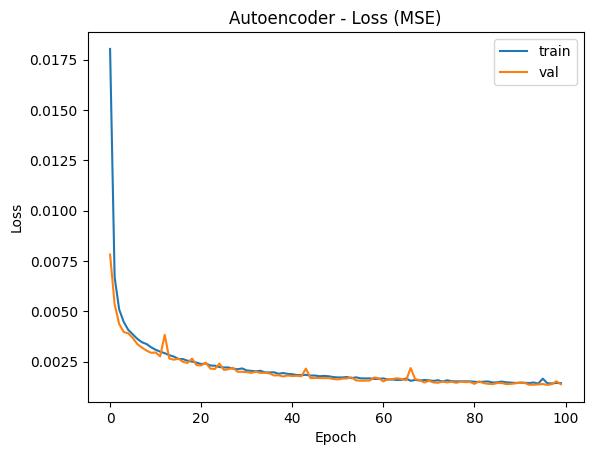

Mejor época (por val_loss): 97
Mejor val_loss: 0.001349


In [34]:
# Representación del loss


import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.plot(history_ae.history["loss"])
plt.plot(history_ae.history["val_loss"])
plt.title("Autoencoder - Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["train", "val"])
plt.show()

best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
best_val_loss = float(np.min(history_ae.history["val_loss"]))
print(f"Mejor época (por val_loss): {best_epoch}")
print(f"Mejor val_loss: {best_val_loss:.6f}")

# CONCLUSIÓN
<br>
<br>
El autoencoder convolucional entrenado presenta un comportamiento estable y consistente, logrando reconstrucciones de buena calidad con un número de parámetros moderado. En concreto, el modelo tiene 92.995 parámetros entrenables y aprende a reconstruir imágenes de tamaño 224×224×3 a partir de una representación comprimida (tras tres etapas de MaxPooling hasta 28×28×64), lo cual confirma que el codificador está extrayendo características relevantes y el decodificador es capaz de recuperar la estructura original.
<br><br>
En las curvas de pérdida (MSE) se observa una caída pronunciada en las primeras épocas y una mejora progresiva posterior, con curvas de entrenamiento y validación muy cercanas durante casi todo el proceso. Esto indica buena generalización (no hay una separación clara entre train y val), y por tanto no se aprecia un sobreentrenamiento significativo. Las pequeñas oscilaciones puntuales en validación son normales, pero el mínimo alcanzado se mantiene y el modelo converge correctamente.
<br><br>
Se entrenaron las 100 épocas completas porque el criterio de EarlyStopping no detuvo el proceso: el val_loss siguió mejorando (aunque lentamente) hasta muy cerca del final, alcanzando su mejor valor en la época 97 con un val_loss = 0.001349. En resumen, el autoencoder converge, reduce el error de reconstrucción de forma efectiva y mantiene un rendimiento similar entre entrenamiento y validación, lo que sugiere que ha aprendido una codificación útil de las imágenes sin degradar la capacidad de reconstrucción en datos no vistos.

### 4.2. Evaluación del autoencoder

La evaluación del modelo obtenido puede hacerse en este caso tanto de forma cuantitativa (calculando el MSE entre las imágenes originales y reconstruídas del conjunto de test) como cualitativa (mostrando imágenes originales y reconstruídas).

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
    <strong>Ejercicio [1 punto]:</strong> Realizar las siguientes operaciones para evaluar las prestaciones del modelo obtenido:
    <ul>
        <li>Partiendo del conjunto de test obtenido en el primer apartado de la practica:
            <ul>
                <li>Llevar a cabo el reescalado de los datos utilizando la capa <code>normalization_layer</code> tal y como se ha hecho con los conjuntos de entrenamiento y test al inicio de este bloque.</li>
                <li>Generar el conjunto de datos <code>test_data_auto</code> en el que las imágenes sean también el objetivo y substituyan a las etiquetas. </li>
            </ul></li>
        <li>Realizar la evaluación del modelo una vez ha finalizado el entrenamiento para mostrar la pérdida final a partir de los datos de test.</li>
        <li>Imprimir por pantalla 4 parejas de imágenes (original y reconstruída). Nota: a la hora de representar las imágenes correctamente, recordad que su rango dinámico deben ser números enteros entre 0 y 255.</li>
    </ul>
    Preguntas: ¿Consideras que la reconstrucción es adecuada? ¿Qué <i>ratio</i> de compresión se consigue con este autoencoder? Consideramos como <i>ratio</i> de compresión la relación entre el tamaño original de la imagen (224,224,3) y el de la representación más perqueña que llega a hacer el codificador (tamaño de la salida de su última capa).

In [35]:
# Normalización de los datos


# Reescalado del conjunto de test a (0,1)
normalized_test_data = test_data.map(lambda x, y: (normalization_layer(x), y))

# Dataset autoencoder: objetivo = la propia imagen
test_data_auto = normalized_test_data.map(lambda x, y: (x, x))

# Comprobación rápida (opcional)
image_batch, label_batch = iter(test_data_auto).get_next()
print("Batch imágenes:", image_batch.shape)
print("Batch etiquetas:", label_batch.shape)



Batch imágenes: (32, 224, 224, 3)
Batch etiquetas: (32, 224, 224, 3)


In [36]:
# Evaluación del modelo


test_mse = autoencoder.evaluate(test_data_auto, verbose=1)
print(f"Test MSE (loss): {test_mse:.6f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0014
Test MSE (loss): 0.001367


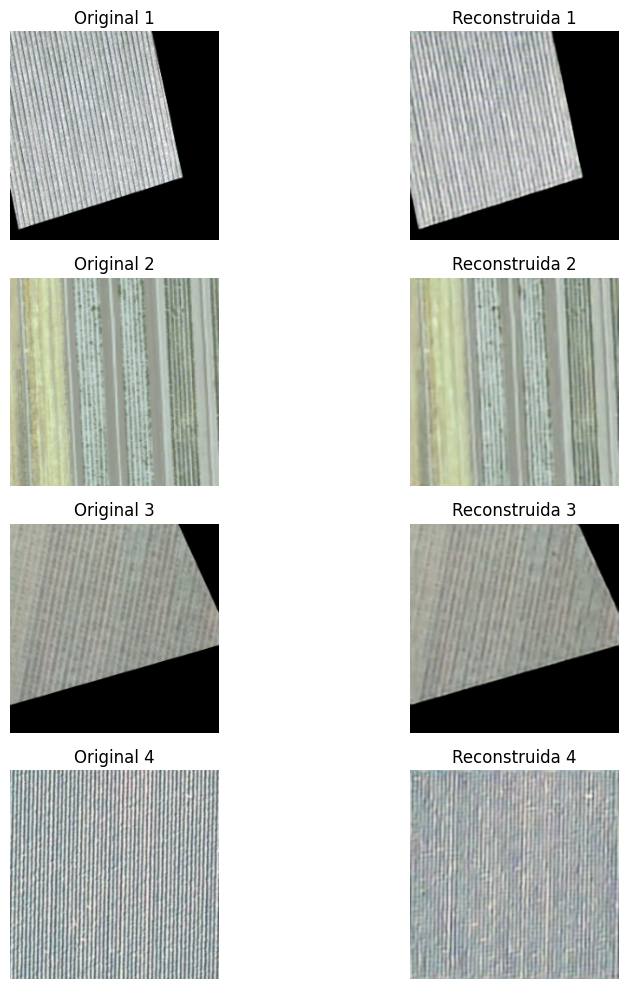

In [37]:
# Visualización de los datos

# Tomar un batch del test
x_batch, _ = next(iter(test_data_auto))   # x_batch está en [0,1]

# Reconstrucción
x_recon = autoencoder.predict(x_batch, verbose=0)  # también en [0,1]

# Para visualizar: convertir a enteros [0,255]
x_orig_vis = np.clip(x_batch.numpy() * 255.0, 0, 255).astype(np.uint8)
x_recon_vis = np.clip(x_recon * 255.0, 0, 255).astype(np.uint8)

# Mostrar 4 parejas (8 imágenes en total)
n = 4
plt.figure(figsize=(10, 2.5*n))

for i in range(n):
    # Original
    ax = plt.subplot(n, 2, 2*i + 1)
    ax.imshow(x_orig_vis[i])
    ax.set_title(f"Original {i+1}")
    ax.axis("off")

    # Reconstruida
    ax = plt.subplot(n, 2, 2*i + 2)
    ax.imshow(x_recon_vis[i])
    ax.set_title(f"Reconstruida {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Respuestas:</strong>
<br><br>

### **¿Consideras que la reconstrucción es adecuada?**
<br><br>
Sí, en general es adecuada para un autoencoder sencillo:
<br><br>
* Cualitativamente (imágenes): se preservan bien las formas globales y patrones dominantes (orientación, bandas/estructuras principales). Se nota una suavización y pérdida de detalle fino/contraste (algo normal en reconstrucción), y en alguna pareja aparece ligero “blur”/artefactos en zonas con texturas muy repetitivas.

* Cuantitativamente: el Test MSE ≈ 0.001367 (en imágenes normalizadas a
0,1) es bajo, lo que respalda que la reconstrucción global es buena.
<br><br>
**En resumen:** reconstruye bien la información principal, aunque no recupera perfectamente detalles finos.
<br><br>

### **¿Qué ratio de compresión se consigue con este autoencoder? Consideramos como ratio de compresión la relación entre el tamaño original de la imagen (224,224,3) y el de la representación más perqueña que llega a hacer el codificador (tamaño de la salida de su última capa).**
<br><br>
Se define el **ratio de compresión** como la relación entre el tamaño original de la imagen y el tamaño de la representación mínima alcanzada por el codificador (salida de su última capa).
<br><br>
***Tamaño original de entrada:***
* 224×224×3=150528
<br><br>

***Tamaño representación mínima:***
* 28×28×64=50176

<br><br>
***Ratio de compresión (original / codificado):***
* 150528​ / 50176 = 3


<br><br>
**Resultado:** el autoencoder logra un ratio de compresión de **3:1**, es decir, la representación interna es aproximadamente **3 veces más pequeña** que la imagen original (en número de valores).

<br><br>
</div>

## 5. Transfer learning con modelos eficientes: EfficientNetB0 (2 puntos)

Las redes neuronales convolucionales profundas nos brindan la posibilidad de mejorar la capacidad de aprendizaje de un modelo. Arquitecturas clásicas como VGG16 fueron pioneras, pero hoy en día existen familias de modelos mucho más optimizadas, como **EfficientNet**, que logran mejores precisiones con muchos menos parámetros.

### 5.1. Transfer Learning
En este apartado, aplicaremos [transfer learning](https://keras.io/guides/transfer_learning/) utilizando el modelo [EfficientNetB0](https://keras.io/api/applications/efficientnet/#efficientnetb0-function) preentrenado en [Imagenet](http://www.image-net.org/). Lo adaptaremos para clasificar las 21 categorías de nuestra base de datos. Una gran ventaja de EfficientNet en Keras es que **ya incluye la capa de preprocesamiento (reescalado) internamente**, por lo que podemos pasarle directamente nuestras imágenes en el rango [0, 255].

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio[1 punto]:</strong> Implementa una red siguiendo los siguientes pasos:
    <ul>
        <li>Partir del modelo EfficientNetB0 con los pesos entrenados en Imagenet (sin la parte superior de clasificación, <code>include_top=False</code>) y congelarlos.</li>
        <li>Añadir una capa <code>GlobalAveragePooling2D</code> a la salida del modelo base.</li>
        <li>Añadir una capa densa de 50 neuronas con activación ReLU, seguida de la capa de salida con el número de neuronas adecuado para llevar a cabo la clasificación y la función de activación correspondiente.</li>
    </ul>
Compilar y entrenar el modelo siguiendo las siguientes indicaciones:
     <ul>
         <li>Utilizar el optimizador Adam con <i>learning rate</i> de 0.0001.</li>
         <li>Entrenar durante 100 épocas utilizando <i>EarlyStopping</i> con una persistencia de 10 épocas, monitorizando la <i>accuracy</i> en validación y guardando los mejores pesos.</li>
         <li>Mostrar las gráficas de accuracy y loss (entrenamiento y validación).</li>
         <li>Evaluar el modelo final sobre los datos de test.</li>
    </ul>
    Preguntas a responder: ¿Cuál es el número de parámetros a entrenar? ¿Qué precisión se obtiene comparado con la red convolucional simple del apartado 3? Comenta los resultados y las gráficas de entrenamiento.
</div>

In [38]:
from tensorflow.keras.applications import EfficientNetB0

# Cargar el modelo base preentrenado


num_classes = len(classes)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False  # congelar pesos

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [39]:
# Definición de la red

inputs = tf.keras.Input(shape=(224, 224, 3), name="input_224x224x3")

x = base_model(inputs, training=False)  # importante: training=False al estar congelado
x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
x = tf.keras.layers.Dense(50, activation="relu", name="dense_50")(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="output_softmax")(x)

effnet_model = tf.keras.Model(inputs, outputs, name="EfficientNetB0_TL")

effnet_model.summary()

Model: "EfficientNetB0_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_224x224x3 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 50)             │        64,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 21)             │         1,071 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,114,692 (15.70 MB)

 Trainable params: 65,121 (254.38 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [40]:
# Compilación de la red

opt = tf.keras.optimizers.Adam(learning_rate=1e-4)

effnet_model.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [41]:
# Entrenamiento de la red

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=10,
    mode="max",
    restore_best_weights=True
)

start_time = time.time()

history_eff = effnet_model.fit(
    train_data,
    validation_data=val_data,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

train_time_sec = time.time() - start_time
print(f"Tiempo total entrenamiento: {train_time_sec/60:.2f} min")
print(f"Épocas entrenadas: {len(history_eff.history['loss'])}")

Epoch 1/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 73s 193ms/step - accuracy: 0.4512 - loss: 2.2870 - val_accuracy: 0.7238 - val_loss: 1.5107
Epoch 2/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.8144 - loss: 1.1039 - val_accuracy: 0.8595 - val_loss: 0.7909
Epoch 3/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.8815 - loss: 0.6565 - val_accuracy: 0.8933 - val_loss: 0.5378
Epoch 4/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9039 - loss: 0.4782 - val_accuracy: 0.9119 - val_loss: 0.4191
Epoch 5/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9211 - loss: 0.3797 - val_accuracy: 0.9210 - val_loss: 0.3499
Epoch 6/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9306 - loss: 0.3190 - val_accuracy: 0.9319 - val_loss: 0.3041
Epoch 7/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9377 - loss: 0.2760 - val_accuracy: 0.9390 - val_loss: 0.2702
Epoch 8/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9469 - loss: 0.2408 

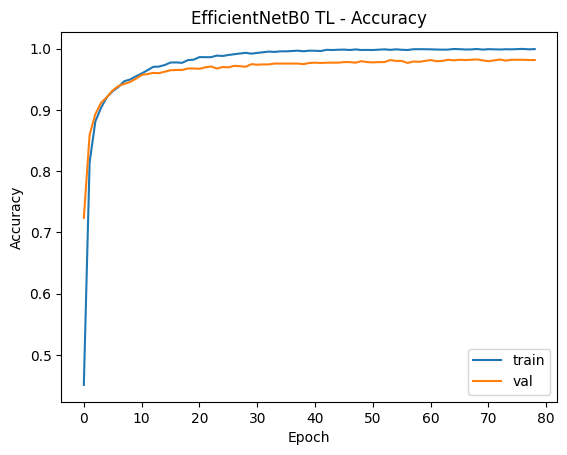

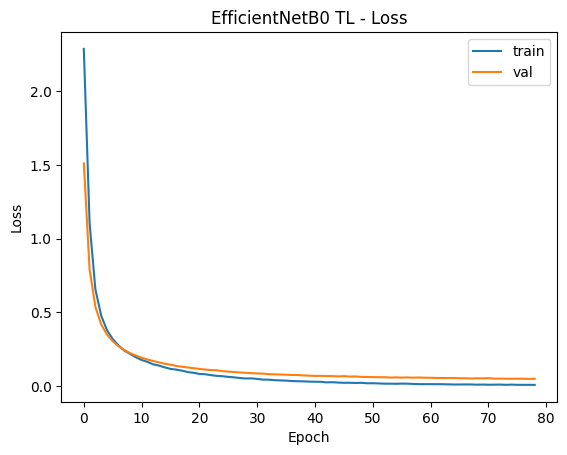

33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 422ms/step - accuracy: 0.9790 - loss: 0.0578
Test loss: 0.0578
Test accuracy: 0.9790
Mejor época (por val_accuracy): 69
Mejor val_accuracy: 0.9824
Mejor val_loss: 0.0487


In [42]:
# Resultados


def plot_history(history, title_prefix=""):
    # Accuracy
    plt.figure()
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"{title_prefix}Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["train", "val"])
    plt.show()

    # Loss
    plt.figure()
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"{title_prefix}Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["train", "val"])
    plt.show()

plot_history(history_eff, title_prefix="EfficientNetB0 TL - ")

test_loss, test_acc = effnet_model.evaluate(test_data, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

best_epoch_acc = int(np.argmax(history_eff.history["val_accuracy"])) + 1
best_val_acc = float(np.max(history_eff.history["val_accuracy"]))
best_val_loss = float(np.min(history_eff.history["val_loss"]))

print(f"Mejor época (por val_accuracy): {best_epoch_acc}")
print(f"Mejor val_accuracy: {best_val_acc:.4f}")
print(f"Mejor val_loss: {best_val_loss:.4f}")

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Respuestas:</strong>
<br><br>

### ***¿Cuál es el número de parámetros a entrenar?***


* Trainable params (a entrenar): 65.121 (El backbone EfficientNetB0 está congelado; los 4.049.571 restantes son no entrenables.)
<br><br>

### ***¿Qué precisión se obtiene comparado con la red convolucional simple del apartado 3?***

* EfficientNetB0 TL (5.1): Test accuracy = 0.9790 (97.90%)

* CNN pequeña: Test accuracy = 0.8657 (86.57%)
<br><br>
**MEJORA: ** 0.9790 − 0.8657 = 0.1133 ≈ ***+11.33 puntos porcentuales***

<br><br>
### ***Comenta los resultados y las gráficas de entrenamiento.***

<br><br>
***EfficientNetB0 TL (5.1)***

* Con muy pocos parámetros entrenables (65k), alcanza mucha precisión (97.9%).

* Las curvas muestran convergencia muy rápida: val_accuracy sube pronto y se mantiene alta, y val_loss baja a valores muy pequeños (mínimo alrededor de 0.0487, según tu salida del 5.1).

* Esto es lo esperado en transfer learning: el backbone preentrenado ya extrae características generales muy potentes y solo se ajusta un clasificador pequeño al nuevo dominio.
<br><br>

***CNN pequeña***

* Obtuvo Test accuracy = 0.8657, con:

  - Mejor época (por val_loss): 69

  - Mejor val_loss: 0.4090

  - Mejor val_accuracy: 0.8743

* Aquí las curvas suelen mostrar aprendizaje estable, pero con menor rendimiento final que EfficientNet: al entrenar “desde cero” (o sin preentrenamiento) necesita aprender representaciones desde los datos del problema, y aunque funciona bien, se queda por debajo del modelo preentrenado.
<br><br>
**CONCLUSIÓN:** EfficientNetB0 TL supera a la CNN pequeña en ~11.33 puntos de accuracy en test, entrenando además muchísimos menos parámetros gracias al preentrenamiento de ImageNet.
<br><br>
</div>

### 5.2. Fine-tunning
Para mejorar los resultados del <i>transfer learning</i>, aplicaremos <i>fine-tunning</i>, que consiste en descongelar el modelo base y reentrenar la red completa durante unas pocas épocas con un <i>learning rate</i> muy pequeño para ajustar los pesos finamente a nuestro dominio.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio[1 punto]:</strong> Volver a compilar el modelo con los siguientes cambios:
    <ul>
        <li>Descongelar los pesos del modelo EfficientNetB0 (<code>base_model_eff.trainable = True</code>).</li>
    </ul>
Compilar y entrenar el modelo siguiendo las siguientes indicaciones:
     <ul>
         <li>Utilizar el optimizador Adam con <i>learning rate</i> de 0.00001.</li>
         <li>Entrenar durante 10 épocas.</li>
         <li>Mostrar las gráficas y realizar la evaluación final sobre los datos de test.</li>
    </ul>
    Comenta los resultados globales del proceso.
</div>

In [43]:
# Definición del modelo

# Fine-tuning: descongelar el modelo base
base_model.trainable = True

print("base_model.trainable =", base_model.trainable)
effnet_model.summary()

base_model.trainable = True


Model: "EfficientNetB0_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_224x224x3 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 50)             │        64,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 21)             │         1,071 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,244,936 (16.19 MB)

 Trainable params: 4,072,669 (15.54 MB)

 Non-trainable params: 42,023 (164.16 KB)

 Optimizer params: 130,244 (508.77 KB)

In [44]:
# Compilación de la red

opt_ft = tf.keras.optimizers.Adam(learning_rate=1e-5)

effnet_model.compile(
    optimizer=opt_ft,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [45]:
# Entrenamiento

start_time = time.time()

history_eff_ft = effnet_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    verbose=1
)

train_time_sec = time.time() - start_time
print(f"Tiempo fine-tuning: {train_time_sec/60:.2f} min")

Epoch 1/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 143s 300ms/step - accuracy: 0.7884 - loss: 0.7597 - val_accuracy: 0.9314 - val_loss: 0.2417
Epoch 2/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 75ms/step - accuracy: 0.9014 - loss: 0.3698 - val_accuracy: 0.9352 - val_loss: 0.2391
Epoch 3/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 75ms/step - accuracy: 0.9422 - loss: 0.2301 - val_accuracy: 0.9443 - val_loss: 0.1961
Epoch 4/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9645 - loss: 0.1560 - val_accuracy: 0.9514 - val_loss: 0.1651
Epoch 5/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9743 - loss: 0.1178 - val_accuracy: 0.9600 - val_loss: 0.1429
Epoch 6/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9819 - loss: 0.0861 - val_accuracy: 0.9662 - val_loss: 0.1262
Epoch 7/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.9887 - loss: 0.0648 - val_accuracy: 0.9690 - val_loss: 0.1146
Epoch 8/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 17s 75ms/step - accuracy: 0.9920 - loss: 0.0510 

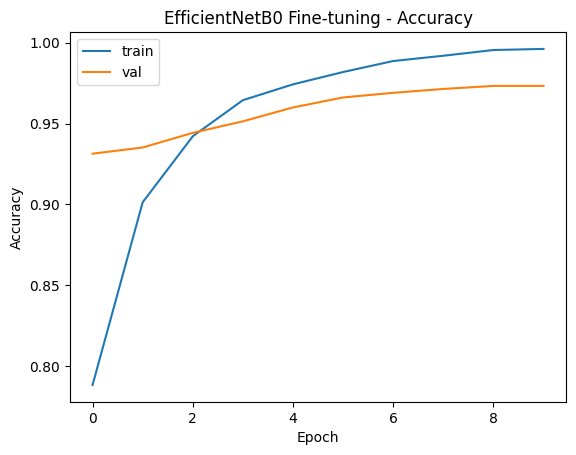

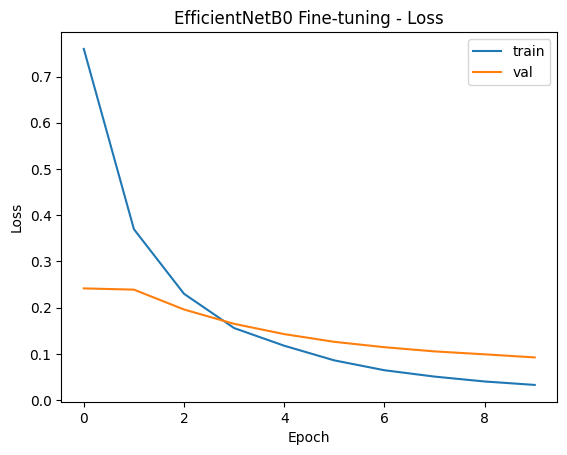

33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step - accuracy: 0.9810 - loss: 0.0797
Test loss (fine-tune): 0.0797
Test accuracy (fine-tune): 0.9810
Mejor época (val_accuracy): 9
Mejor val_accuracy (10 ep): 0.9733


In [46]:
# Resultados

plot_history(history_eff_ft, title_prefix="EfficientNetB0 Fine-tuning - ")

test_loss_ft, test_acc_ft = effnet_model.evaluate(test_data, verbose=1)
print(f"Test loss (fine-tune): {test_loss_ft:.4f}")
print(f"Test accuracy (fine-tune): {test_acc_ft:.4f}")

best_epoch = int(np.argmax(history_eff_ft.history["val_accuracy"])) + 1
best_val_acc = float(np.max(history_eff_ft.history["val_accuracy"]))
print(f"Mejor época (val_accuracy): {best_epoch}")
print(f"Mejor val_accuracy (10 ep): {best_val_acc:.4f}")

<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentarios:</strong>
<br><br>
(Añade tus comentarios substituyendo este texto)
<br><br>
</div>

## 6. Introducción a PyTorch: Red Convolucional Básica (1 punto)

Hasta ahora hemos utilizado TensorFlow/Keras, que nos ofrecen una API de alto nivel muy cómoda mediante los métodos `.fit()` y `.evaluate()`. Sin embargo, en el mundo de la investigación y en gran parte de la industria, **PyTorch** es el <i>framework</i> dominante debido a su flexibilidad y a que permite un control más profundo y "pythonico" del flujo de ejecución.

En PyTorch, nosotros mismos debemos definir cómo los datos pasan por la red (`forward pass`) y cómo iteramos sobre los lotes para actualizar los pesos en lo que llamamos el **bucle de entrenamiento** (*training loop*).

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio [1 punto]:</strong> Implementa una red convolucional sencilla y entrénala usando PyTorch para clasificar nuestra base de datos.
    <ul>
        <li><strong>Carga de datos:</strong> Utiliza <code>torchvision.datasets.ImageFolder</code> y <code>DataLoader</code> para cargar las imágenes de entrenamiento desde la ruta <code>train_dir</code>. Aplica transformaciones para redimensionar a 224x224 y convertir a Tensor (lo cual rescala automáticamente a valores entre 0 y 1). Lotes de tamaño 32.</li>
        <li><strong>Definición del modelo:</strong> Crea una clase que herede de <code>nn.Module</code>. Debe contener:
            <ul>
                <li>Dos capas convolucionales (`nn.Conv2d`), cada una seguida de una activación ReLU y un <i>Max Pooling</i> (`nn.MaxPool2d`).</li>
                <li>Una capa <code>nn.AdaptiveAvgPool2d((1, 1))</code> para colapsar las dimensiones espaciales.</li>
                <li>Una capa lineal de clasificación (`nn.Linear`) con salida a 21 clases.</li>
            </ul>
        </li>
        <li><strong>Bucle de entrenamiento:</strong> Define como función de pérdida <code>nn.CrossEntropyLoss</code> y utiliza el optimizador Adam (lr=0.001). Escribe un bucle de entrenamiento de <strong>5 épocas</strong> que recorra el DataLoader de entrenamiento e imprima por pantalla la pérdida (<i>loss</i>) de cada época.</li>
    </ul>
    Comenta brevemente las diferencias que has notado al programar este modelo en PyTorch respecto a Keras.
</div>

In [49]:
# Imports y paths

import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_dir = "/content/drive/MyDrive/PEC1 UOC Deep Learning/Data/images_train_test_val/train"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [50]:
# Carga de datos (ImageFolder + DataLoader)

BATCH_SIZE = 32

train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  # -> float32 en [0,1]
])

train_ds = datasets.ImageFolder(root=train_dir, transform=train_tfms)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

print("Clases detectadas:", len(train_ds.classes))
print("Ejemplo clases:", train_ds.classes[:5])

Clases detectadas: 21
Ejemplo clases: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings']


In [51]:
# Definición del modelo (nn.Module)

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 224x224 -> 224x224
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 112x112

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 112x112 -> 112x112
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 56x56
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))           # -> (32, 1, 1)
        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)   # (B, 32)
        x = self.classifier(x)    # (B, 21)
        return x

model = SimpleCNN(num_classes=21).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=32, out_features=21, bias=True)
)


In [52]:
# Loss y optimizador

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [53]:
# Bucle de entrenamiento (5 épocas)

EPOCHS = 5

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch}/{EPOCHS} - loss: {epoch_loss:.4f}")

Epoch 1/5 - loss: 3.0010
Epoch 2/5 - loss: 2.8542
Epoch 3/5 - loss: 2.7695
Epoch 4/5 - loss: 2.7164
Epoch 5/5 - loss: 2.6727


<div style="background-color: #fcf2f2; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Comentarios:</strong>
<br><br>

# Diferencias principales que se notan al programar en PyTorch vs Keras:

* En Keras gran parte del flujo está abstraído (model.fit(), model.evaluate()); se define el modelo y Keras gestiona el entrenamiento.

* En PyTorch se controla el proceso: se debe escribir explícitamente el training loop, hacer zero_grad(), forward, calcular loss, backward() y optimizer.step().

* PyTorch es más “pythonico” y flexible (ideal para investigación cuando se requiere una manipulación más granular de parámetros), pero requiere más código y cuidado (modo train()/eval(), mover tensores al device, etc.).


<br><br>
</div>

<div style="background-color: #c3fac4; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>Fuentes:</strong>
<br><br>
Pon aquí las fuentes utilizadas en la elaboración de la PEC (incluyendo herramientas de IA generativa).
<br><br>

Fuentes utilizadas en el ejercicio 1:
- TensorFlow. (s. f.). tf.keras.preprocessing.image_dataset_from_directory (alias: tf.keras.utils.image_dataset_from_directory). Recuperado el 17 de marzo de 2026, de https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory
- Keras. (s. f.). Image data loading. Recuperado el 17 de marzo de 2026, de https://keras.io/api/data_loading/image/
- TensorFlow. (2024, 15 de agosto). Better performance with the tf.data API. Recuperado el 17 de marzo de 2026, de https://www.tensorflow.org/guide/data_performance

Fuentes utilizadas en el ejercicio 2:
- Keras. (2020, 12 de abril). The Sequential model. Recuperado el 17 de marzo de 2026, de https://keras.io/guides/sequential_model/
- Keras. (s. f.). Resizing layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/preprocessing_layers/image_preprocessing/resizing/
- Keras. (s. f.). Rescaling layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/
- Keras. (s. f.). Flatten layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/reshaping_layers/flatten/
- Keras. (s. f.). Dense layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/core_layers/dense/
- Keras. (s. f.). Dropout layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/regularization_layers/dropout/
- Keras. (s. f.). EarlyStopping. Recuperado el 17 de marzo de 2026, de https://keras.io/api/callbacks/early_stopping/
- TensorFlow. (s. f.). tf.keras.optimizers.Adam. Recuperado el 17 de marzo de 2026, de https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam

Fuentes utilizadas en el ejercicio 3:
- Keras. (s. f.). Conv2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/convolution_layers/convolution2d/
- Keras. (s. f.). MaxPooling2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/pooling_layers/max_pooling2d/
- Keras. (s. f.). GlobalAveragePooling2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/pooling_layers/global_average_pooling2d/
- Keras. (s. f.). Dropout layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/regularization_layers/dropout/
- Keras. (s. f.). The Model class. Recuperado el 17 de marzo de 2026, de https://keras.io/api/models/model/
- Keras. (2019, 1 de marzo). The Functional API. Recuperado el 17 de marzo de 2026, de https://keras.io/guides/functional_api/

Fuentes utilizadas en el ejercicio 4:
- Keras. (s. f.). Conv2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/convolution_layers/convolution2d/
- Keras. (s. f.). MaxPooling2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/pooling_layers/max_pooling2d/
- Keras. (s. f.). Conv2DTranspose layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/convolution_layers/convolution2d_transpose/
- Keras. (s. f.). UpSampling2D layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/reshaping_layers/up_sampling2d/
- Keras. (s. f.). Rescaling layer. Recuperado el 17 de marzo de 2026, de https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/
- TensorFlow. (s. f.). tf.keras.losses.MeanSquaredError. Recuperado el 17 de marzo de 2026, de https://www.tensorflow.org/api_docs/python/tf/keras/losses/MeanSquaredError
- Keras. (s. f.). EarlyStopping. Recuperado el 17 de marzo de 2026, de https://keras.io/api/callbacks/early_stopping/
- TensorFlow. (s. f.). tf.keras.optimizers.Adam. Recuperado el 17 de marzo de 2026, de https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam
- Keras. (s. f.). The Model class. Recuperado el 17 de marzo de 2026, de https://keras.io/api/models/model/
- Keras. (2019, 1 de marzo). The Functional API. Recuperado el 17 de marzo de 2026, de https://keras.io/guides/functional_api/

Fuentes utilizadas en el ejercicio 5:
- Keras. (s. f.). EfficientNet B0 to B7. Recuperado el 17 de marzo de 2026, de https://keras.io/api/applications/efficientnet/
- Keras. (2020, 15 de abril). Transfer learning & fine-tuning. Recuperado el 17 de marzo de 2026, de https://keras.io/guides/transfer_learning/
- Keras. (2020, 30 de junio). Image classification via fine-tuning with EfficientNet. Recuperado el 17 de marzo de 2026, de https://keras.io/examples/vision/image_classification_efficientnet_fine_tuning/

Fuentes utilizadas en el ejercicio 6:
- Torchvision. (s. f.). ImageFolder. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
- Torchvision. (s. f.). Resize. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/vision/main/generated/torchvision.transforms.Resize.html
- Torchvision. (s. f.). ToTensor. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html
- PyTorch. (s. f.). Datasets & DataLoaders. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
- PyTorch. (s. f.). torch.utils.data.DataLoader. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/data.html
- PyTorch. (s. f.). torch.nn.Conv2d. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
- PyTorch. (s. f.). torch.nn.MaxPool2d. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html
- PyTorch. (s. f.). torch.nn.AdaptiveAvgPool2d. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html
- PyTorch. (s. f.). torch.nn.Linear. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html
- PyTorch. (s. f.). torch.nn.CrossEntropyLoss. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- PyTorch. (s. f.). torch.optim.Adam. Recuperado el 17 de marzo de 2026, de https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html

</div>